In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

base_dir = r"C:\Users\VICTUS\Downloads\تدريبات علي ال Jupeter\Task\Task 5"
matches = glob.glob(os.path.join(base_dir, "**", "integrated_healthcare_dataset.csv"), recursive=True)

if len(matches) > 0:
    DATA_PATH = matches[0]
elif os.path.exists("integrated_healthcare_dataset.csv"):
    DATA_PATH = "integrated_healthcare_dataset.csv"
else:
    raise FileNotFoundError(f"لم يتم العثور على integrated_healthcare_dataset.csv داخل {base_dir}")

print("Loaded file from:", DATA_PATH)
df = pd.read_csv(DATA_PATH)

target_cols = [
    "ISO3",
    "Country",
    "Year",
    "Financial_Hardship_Total_Pct",
    "Large_Spending_Pct",
    "Impoverishing_Spending_Pct",
    "Q1_Poorest_Pct",
    "Q2_Pct",
    "Q3_Pct",
    "Q4_Pct",
    "Q5_Richest_Pct",
    "Equity_Gap_Pct_Points",
    "UHC_Service_Coverage_Index",
    "OOP_Pct_Current_Health_Exp",
    "GDP_Per_Capita_PPP_2021",
]

print("\n=== 1. Dataset Overview ===")
print(f"Total Rows: {len(df)} | Unique Countries (ISO3): {df['ISO3'].nunique()} | Unique Years: {df['Year'].nunique()}")
print(f"Overall Year Range: {df['Year'].min()} to {df['Year'].max()}")

fh_sub = df[df["Financial_Hardship_Total_Pct"].notna()]
print(
    f"Financial Hardship Subset: {len(fh_sub)} observations | "
    f"{fh_sub['ISO3'].nunique()} countries | "
    f"Survey Years: {fh_sub['Year'].nunique()} ({fh_sub['Year'].min()} to {fh_sub['Year'].max()})"
)

print("\n=== 2. Data Types & Coverage (Available vs Missing) ===")
num_cols = target_cols[3:]
coverage_df = pd.DataFrame({
    "Dtype": df[target_cols].dtypes,
    "Available_N": df[target_cols].notna().sum(),
    "Missing_N": df[target_cols].isna().sum(),
    "Missing_Pct": (df[target_cols].isna().mean() * 100).round(2),
})
print(coverage_df)

print("\n=== 3. Descriptive Statistics (Mean, Median, Std, Min, Max) ===")
desc_df = df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).T.round(2)
print(desc_df)

print("\n=== 4. Pairwise Common Observations with External Indicators ===")
for ext_col in ["UHC_Service_Coverage_Index", "OOP_Pct_Current_Health_Exp", "GDP_Per_Capita_PPP_2021"]:
    pair_sub = df[["ISO3", "Year", "Financial_Hardship_Total_Pct", ext_col]].dropna()
    print(
        f"Financial_Hardship_Total_Pct vs {ext_col}: "
        f"N = {len(pair_sub)} | Countries = {pair_sub['ISO3'].nunique()} | "
        f"Years = {int(pair_sub['Year'].min())}–{int(pair_sub['Year'].max())}"
    )

Loaded file from: C:\Users\VICTUS\Downloads\تدريبات علي ال Jupeter\Task\Task 5\integrated_healthcare_dataset.csv

=== 1. Dataset Overview ===
Total Rows: 12855 | Unique Countries (ISO3): 196 | Unique Years: 66
Overall Year Range: 1960 to 2025
Financial Hardship Subset: 1079 observations | 165 countries | Survey Years: 39 (1985 to 2024)

=== 2. Data Types & Coverage (Available vs Missing) ===
                                Dtype  Available_N  Missing_N  Missing_Pct
ISO3                           object        12855          0         0.00
Country                        object        12855          0         0.00
Year                            int64        12855          0         0.00
Financial_Hardship_Total_Pct  float64         1079      11776        91.61
Large_Spending_Pct            float64         1056      11799        91.79
Impoverishing_Spending_Pct    float64         1056      11799        91.79
Q1_Poorest_Pct                float64         1038      11817        91.93
Q2_Pc

=== 1. Financial Hardship Indicators: Detailed Distribution Summary ===
                   Indicator  N_Obs  N_Countries Year_Range  Mean  Median   Std   IQR  Min   Max  Skewness  Upper_Fence_1.5IQR  Potential_Outliers_Count
Financial_Hardship_Total_Pct   1079          165  1985–2024 20.56   16.61 12.65 15.59  0.0 77.45      1.31               50.36                        36
          Large_Spending_Pct   1056          162  1985–2024  3.63    3.06  2.44  3.04  0.0 15.85      1.34                9.39                        34
  Impoverishing_Spending_Pct   1056          162  1985–2024 16.93   12.57 12.12 14.28  0.0 73.89      1.55               43.82                        46

Top 5 Highest Observations for Financial_Hardship_Total_Pct:
ISO3  Country  Year  Financial_Hardship_Total_Pct
 BDI  Burundi  2006                         77.45
 NER    Niger  2007                         74.51
 VNM Viet Nam  1992                         71.55
 BDI  Burundi  1998                         70.47
 TGO

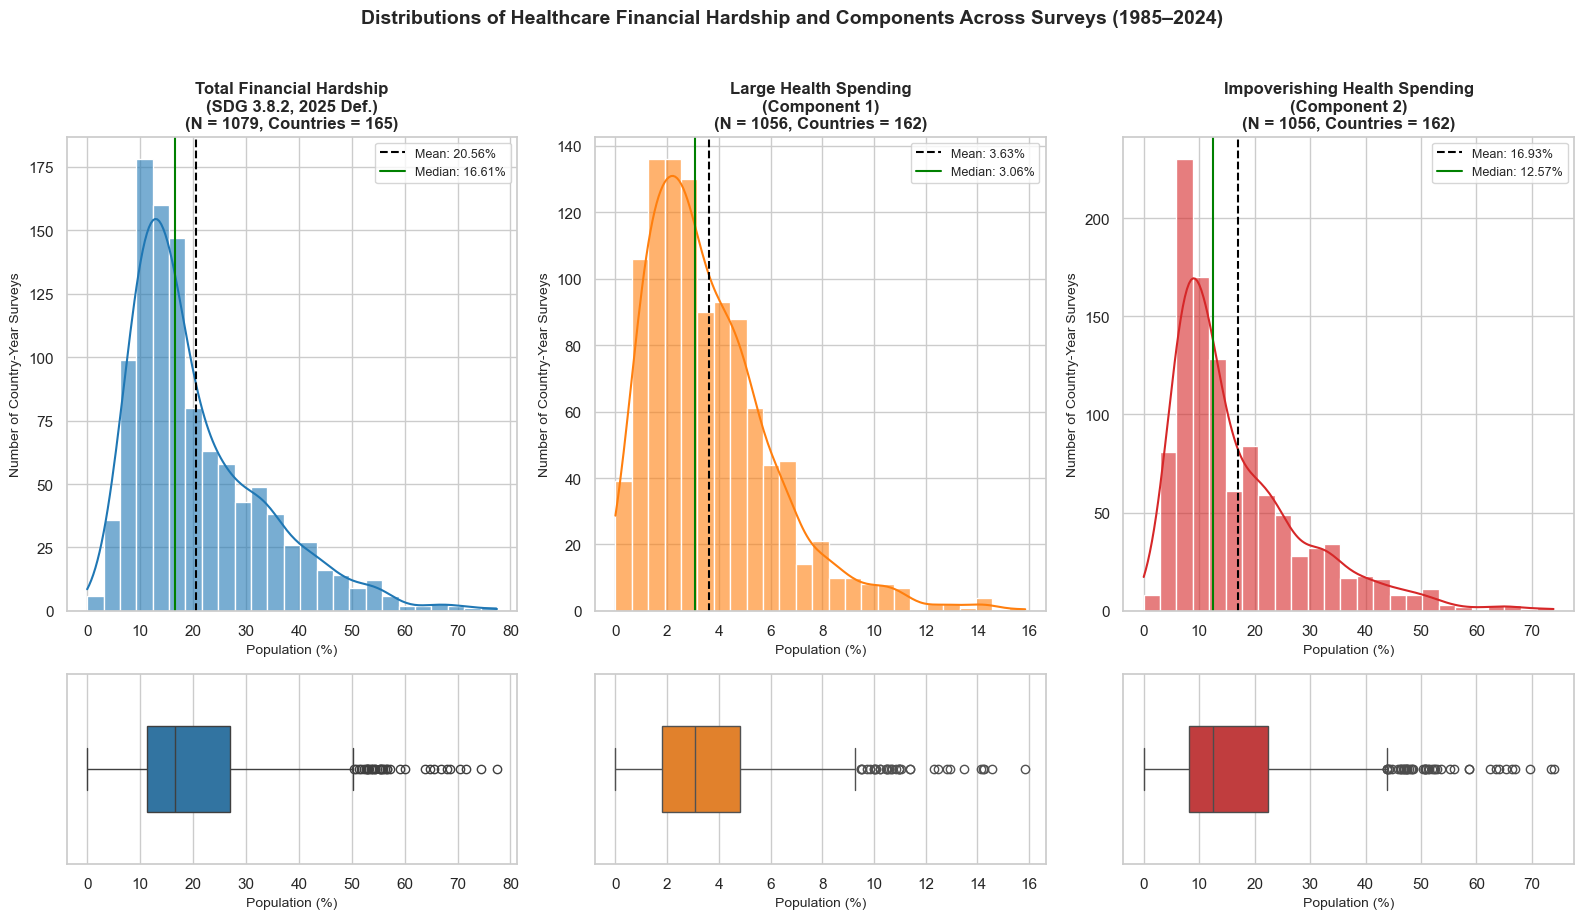

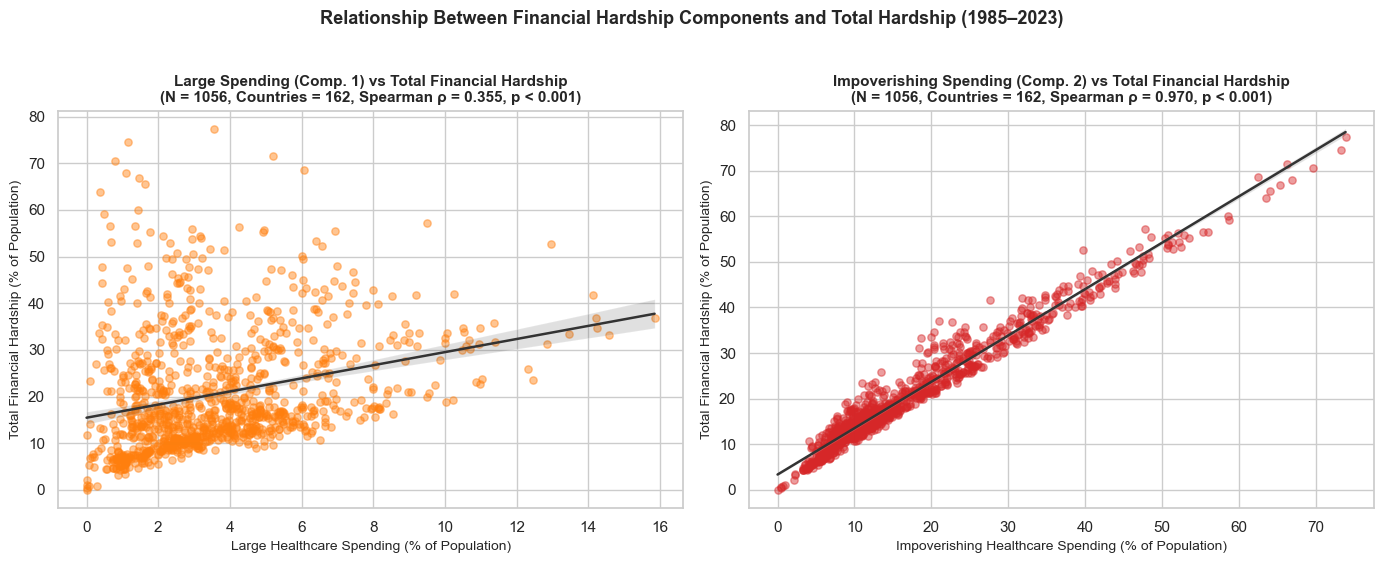

In [ ]:
fh_cols = [
    "Financial_Hardship_Total_Pct",
    "Large_Spending_Pct",
    "Impoverishing_Spending_Pct",
]

fh_stats_list = []
for col in fh_cols:
    sub = df[["ISO3", "Country", "Year", col]].dropna()
    q25, q75 = sub[col].quantile(0.25), sub[col].quantile(0.75)
    iqr = q75 - q25
    upper_fence = q75 + 1.5 * iqr
    outliers = sub[sub[col] > upper_fence]
    fh_stats_list.append({
        "Indicator": col,
        "N_Obs": len(sub),
        "N_Countries": sub["ISO3"].nunique(),
        "Year_Range": f"{int(sub['Year'].min())}–{int(sub['Year'].max())}",
        "Mean": round(sub[col].mean(), 2),
        "Median": round(sub[col].median(), 2),
        "Std": round(sub[col].std(), 2),
        "IQR": round(iqr, 2),
        "Min": round(sub[col].min(), 2),
        "Max": round(sub[col].max(), 2),
        "Skewness": round(sub[col].skew(), 2),
        "Upper_Fence_1.5IQR": round(upper_fence, 2),
        "Potential_Outliers_Count": len(outliers),
    })

fh_stats_df = pd.DataFrame(fh_stats_list)
print("=== 1. Financial Hardship Indicators: Detailed Distribution Summary ===")
print(fh_stats_df.to_string(index=False))

for col in fh_cols:
    top5 = df[["ISO3", "Country", "Year", col]].dropna().sort_values(col, ascending=False).head(5)
    print(f"\nTop 5 Highest Observations for {col}:")
    print(top5.to_string(index=False))

comp_sub = df[["ISO3", "Country", "Year"] + fh_cols].dropna()
print(f"\n=== 2. Component Relationships (Common Sample: N = {len(comp_sub)}, Countries = {comp_sub['ISO3'].nunique()}) ===")

pairs_step3 = [
    ("Large_Spending_Pct", "Financial_Hardship_Total_Pct"),
    ("Impoverishing_Spending_Pct", "Financial_Hardship_Total_Pct"),
    ("Large_Spending_Pct", "Impoverishing_Spending_Pct"),
]

for col_x, col_y in pairs_step3:
    rho, p_spear = stats.spearmanr(comp_sub[col_x], comp_sub[col_y])
    r_pear, p_pear = stats.pearsonr(comp_sub[col_x], comp_sub[col_y])
    print(
        f"{col_x} vs {col_y}:\n"
        f"   Spearman rho = {rho:.4f} (p = {p_spear:.4e}) | Pearson r = {r_pear:.4f} (p = {p_pear:.4e})"
    )

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 9), gridspec_kw={"height_ratios": [3, 1.2]})

titles_map = {
    "Financial_Hardship_Total_Pct": "Total Financial Hardship\n(SDG 3.8.2, 2025 Def.)",
    "Large_Spending_Pct": "Large Health Spending\n(Component 1)",
    "Impoverishing_Spending_Pct": "Impoverishing Health Spending\n(Component 2)",
}
colors_map = ["#1f77b4", "#ff7f0e", "#d62728"]

for i, col in enumerate(fh_cols):
    data_col = df[col].dropna()
    n_obs = len(data_col)
    n_cnt = df.loc[df[col].notna(), "ISO3"].nunique()
    mean_v, med_v = data_col.mean(), data_col.median()

    # Histogram + KDE
    sns.histplot(data_col, kde=True, ax=axes[0, i], color=colors_map[i], bins=25, alpha=0.6)
    axes[0, i].axvline(mean_v, color="black", linestyle="--", linewidth=1.5, label=f"Mean: {mean_v:.2f}%")
    axes[0, i].axvline(med_v, color="green", linestyle="-", linewidth=1.5, label=f"Median: {med_v:.2f}%")
    axes[0, i].set_title(f"{titles_map[col]}\n(N = {n_obs}, Countries = {n_cnt})", fontsize=12, fontweight="bold")
    axes[0, i].set_xlabel("Population (%)", fontsize=10)
    axes[0, i].set_ylabel("Number of Country-Year Surveys", fontsize=10)
    axes[0, i].legend(fontsize=9)

    
    sns.boxplot(x=data_col, ax=axes[1, i], color=colors_map[i], width=0.45)
    axes[1, i].set_xlabel("Population (%)", fontsize=10)
    axes[1, i].set_ylabel("")

plt.suptitle(
    "Distributions of Healthcare Financial Hardship and Components Across Surveys (1985–2024)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("financial_hardship_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

rho1, p1 = stats.spearmanr(comp_sub["Large_Spending_Pct"], comp_sub["Financial_Hardship_Total_Pct"])
sns.regplot(
    data=comp_sub,
    x="Large_Spending_Pct",
    y="Financial_Hardship_Total_Pct",
    ax=axes[0],
    scatter_kws={"alpha": 0.45, "color": "#ff7f0e", "s": 28},
    line_kws={"color": "#333333", "linewidth": 1.8},
)
axes[0].set_title(
    f"Large Spending (Comp. 1) vs Total Financial Hardship\n"
    f"(N = {len(comp_sub)}, Countries = {comp_sub['ISO3'].nunique()}, Spearman ρ = {rho1:.3f}, p < 0.001)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Large Healthcare Spending (% of Population)", fontsize=10)
axes[0].set_ylabel("Total Financial Hardship (% of Population)", fontsize=10)

rho2, p2 = stats.spearmanr(comp_sub["Impoverishing_Spending_Pct"], comp_sub["Financial_Hardship_Total_Pct"])
sns.regplot(
    data=comp_sub,
    x="Impoverishing_Spending_Pct",
    y="Financial_Hardship_Total_Pct",
    ax=axes[1],
    scatter_kws={"alpha": 0.45, "color": "#d62728", "s": 28},
    line_kws={"color": "#333333", "linewidth": 1.8},
)
axes[1].set_title(
    f"Impoverishing Spending (Comp. 2) vs Total Financial Hardship\n"
    f"(N = {len(comp_sub)}, Countries = {comp_sub['ISO3'].nunique()}, Spearman ρ = {rho2:.3f}, p < 0.001)",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Impoverishing Healthcare Spending (% of Population)", fontsize=10)
axes[1].set_ylabel("Total Financial Hardship (% of Population)", fontsize=10)

plt.suptitle(
    "Relationship Between Financial Hardship Components and Total Hardship (1985–2023)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("large_vs_impoverishing_spending.png", dpi=300, bbox_inches="tight")
plt.show()

=== 1. Wealth Quintiles Coverage: N = 1038 surveys | Countries = 162 | Years = 1985–2024 ===
            Indicator    N  Countries  Mean  Median   Std   IQR    Min    Max  Skewness
       Q1_Poorest_Pct 1038        162 54.69   53.42 21.92 32.45   0.00 100.00      0.14
               Q2_Pct 1038        162 29.32   18.79 27.23 42.51   0.00 100.00      0.92
               Q3_Pct 1038        162 11.87    4.02 18.75 10.13   0.00 100.00      2.40
               Q4_Pct 1038        162  5.20    1.90 10.90  4.15   0.00  90.93      4.77
       Q5_Richest_Pct 1038        162  2.65    1.38  4.12  2.55   0.00  45.76      4.49
Equity_Gap_Pct_Points 1038        162 52.05   50.59 22.48 31.86 -28.91  99.75      0.04

=== 2. Statistical Hypothesis Tests Across Wealth Quintiles ===
Friedman Test (5 Paired Quintiles, N = 1038): Chi2 = 3301.95, p = 0.0000e+00
Kruskal-Wallis Test (5 Quintiles): H = 2846.52, p = 0.0000e+00
Wilcoxon Signed-Rank Test (Q1 Poorest vs Q5 Richest): W = 246.00, p = 9.1356e-171

===

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_15452\3201545960.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


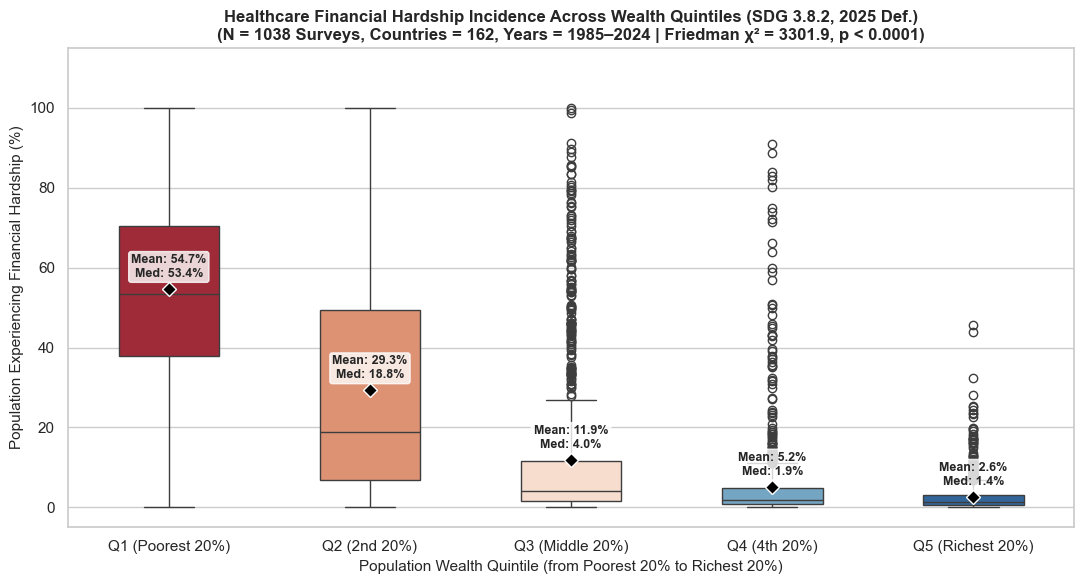

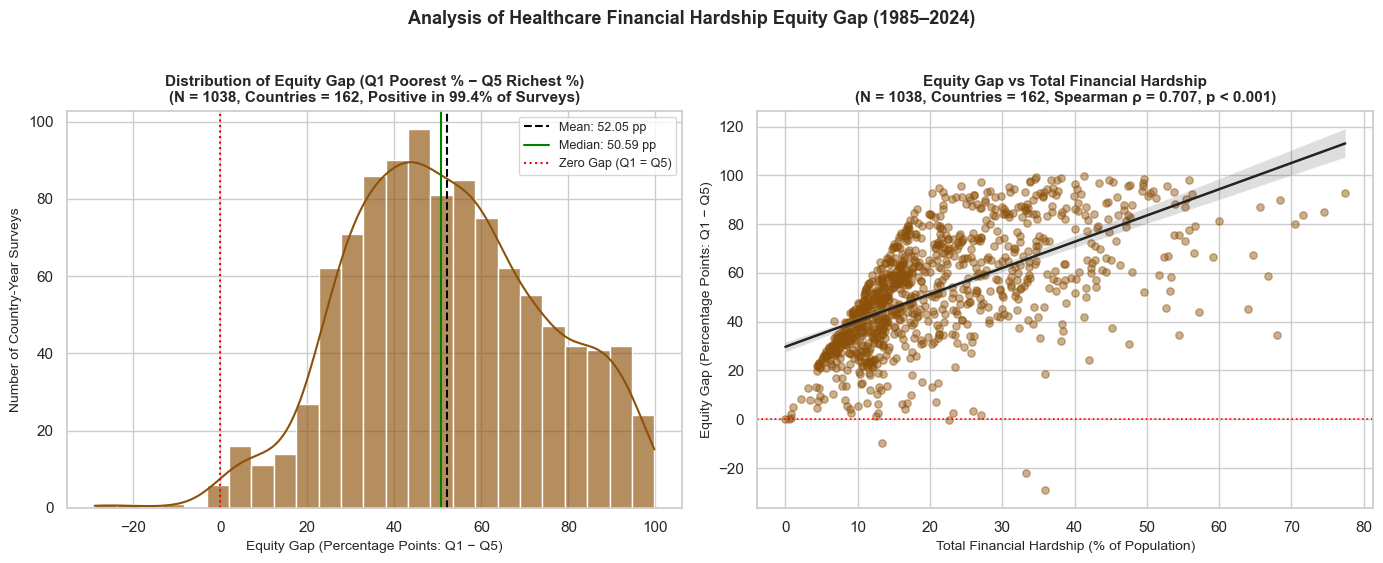

In [ ]:
q_cols = ["Q1_Poorest_Pct", "Q2_Pct", "Q3_Pct", "Q4_Pct", "Q5_Richest_Pct"]
q_sub = df[
    [
        "ISO3",
        "Country",
        "Year",
        "Financial_Hardship_Total_Pct",
        "Large_Spending_Pct",
        "Impoverishing_Spending_Pct",
    ]
    + q_cols
    + ["Equity_Gap_Pct_Points"]
].dropna(subset=q_cols)

print(
    f"=== 1. Wealth Quintiles Coverage: N = {len(q_sub)} surveys | "
    f"Countries = {q_sub['ISO3'].nunique()} | Years = {int(q_sub['Year'].min())}–{int(q_sub['Year'].max())} ==="
)

q_stats = []
for col in q_cols + ["Equity_Gap_Pct_Points"]:
    s = q_sub[col]
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    q_stats.append({
        "Indicator": col,
        "N": len(s),
        "Countries": q_sub["ISO3"].nunique(),
        "Mean": round(s.mean(), 2),
        "Median": round(s.median(), 2),
        "Std": round(s.std(), 2),
        "IQR": round(q75 - q25, 2),
        "Min": round(s.min(), 2),
        "Max": round(s.max(), 2),
        "Skewness": round(s.skew(), 2),
    })

q_stats_df = pd.DataFrame(q_stats)
print(q_stats_df.to_string(index=False))

friedman_stat, friedman_p = stats.friedmanchisquare(
    q_sub["Q1_Poorest_Pct"], q_sub["Q2_Pct"], q_sub["Q3_Pct"], q_sub["Q4_Pct"], q_sub["Q5_Richest_Pct"]
)
kruskal_stat, kruskal_p = stats.kruskal(
    q_sub["Q1_Poorest_Pct"], q_sub["Q2_Pct"], q_sub["Q3_Pct"], q_sub["Q4_Pct"], q_sub["Q5_Richest_Pct"]
)
wilcoxon_stat, wilcoxon_p = stats.wilcoxon(q_sub["Q1_Poorest_Pct"], q_sub["Q5_Richest_Pct"])

print("\n=== 2. Statistical Hypothesis Tests Across Wealth Quintiles ===")
print(f"Friedman Test (5 Paired Quintiles, N = {len(q_sub)}): Chi2 = {friedman_stat:.2f}, p = {friedman_p:.4e}")
print(f"Kruskal-Wallis Test (5 Quintiles): H = {kruskal_stat:.2f}, p = {kruskal_p:.4e}")
print(f"Wilcoxon Signed-Rank Test (Q1 Poorest vs Q5 Richest): W = {wilcoxon_stat:.2f}, p = {wilcoxon_p:.4e}")

q1_gt_q5 = (q_sub["Q1_Poorest_Pct"] > q_sub["Q5_Richest_Pct"]).sum()
q1_eq_q5 = (q_sub["Q1_Poorest_Pct"] == q_sub["Q5_Richest_Pct"]).sum()
q1_lt_q5 = (q_sub["Q1_Poorest_Pct"] < q_sub["Q5_Richest_Pct"]).sum()
q2_gt_q1 = (q_sub["Q2_Pct"] > q_sub["Q1_Poorest_Pct"]).sum()

print("\n=== 3. Equity Gap Direction & Cross-Quintile Patterns ===")
print(f"Positive Equity Gap (Q1 > Q5): {q1_gt_q5} surveys ({q1_gt_q5/len(q_sub)*100:.2f}%)")
print(f"Zero Equity Gap (Q1 == Q5):    {q1_eq_q5} surveys ({q1_eq_q5/len(q_sub)*100:.2f}%)")
print(f"Negative Equity Gap (Q1 < Q5): {q1_lt_q5} surveys ({q1_lt_q5/len(q_sub)*100:.2f}%)")
print(f"Surveys where Q2 > Q1 (2nd Quintile higher than Poorest): {q2_gt_q1} surveys ({q2_gt_q1/len(q_sub)*100:.2f}%)")

print("\nNegative Equity Gap Surveys (Q1 < Q5):")
print(
    q_sub[q_sub["Equity_Gap_Pct_Points"] < 0][
        ["ISO3", "Country", "Year", "Q1_Poorest_Pct", "Q5_Richest_Pct", "Equity_Gap_Pct_Points"]
    ].to_string(index=False)
)

print("\n=== 4. Equity Gap Correlations with Financial Hardship Indicators ===")
for target in [
    "Financial_Hardship_Total_Pct",
    "Impoverishing_Spending_Pct",
    "Large_Spending_Pct",
    "Q1_Poorest_Pct",
    "Q5_Richest_Pct",
]:
    sub_corr = q_sub[["Equity_Gap_Pct_Points", target]].dropna()
    rho, p_val = stats.spearmanr(sub_corr["Equity_Gap_Pct_Points"], sub_corr[target])
    r_p, p_p = stats.pearsonr(sub_corr["Equity_Gap_Pct_Points"], sub_corr[target])
    print(
        f"Equity_Gap_Pct_Points vs {target} (N={len(sub_corr)}): "
        f"Spearman rho = {rho:.4f} (p = {p_val:.4e}) | Pearson r = {r_p:.4f}"
    )


q_melted = q_sub.melt(
    id_vars=["ISO3", "Country", "Year"],
    value_vars=q_cols,
    var_name="Wealth_Quintile",
    value_name="Hardship_Pct",
)
q_labels_map = {
    "Q1_Poorest_Pct": "Q1 (Poorest 20%)",
    "Q2_Pct": "Q2 (2nd 20%)",
    "Q3_Pct": "Q3 (Middle 20%)",
    "Q4_Pct": "Q4 (4th 20%)",
    "Q5_Richest_Pct": "Q5 (Richest 20%)",
}
q_melted["Quintile_Label"] = q_melted["Wealth_Quintile"].map(q_labels_map)

fig, ax = plt.subplots(figsize=(11, 6))
palette_q = ["#b2182b", "#ef8a62", "#fddbc7", "#67a9cf", "#2166ac"]
sns.boxplot(
    data=q_melted,
    x="Quintile_Label",
    y="Hardship_Pct",
    palette=palette_q,
    width=0.5,
    ax=ax,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "white",
        "markersize": 7,
        "label": "Mean",
    },
)

means_q = [q_sub[c].mean() for c in q_cols]
medians_q = [q_sub[c].median() for c in q_cols]
for idx, (m_val, med_val) in enumerate(zip(means_q, medians_q)):
    ax.text(
        idx,
        m_val + 3.0,
        f"Mean: {m_val:.1f}%\nMed: {med_val:.1f}%",
        ha="center",
        fontsize=9,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8),
    )

ax.set_title(
    f"Healthcare Financial Hardship Incidence Across Wealth Quintiles (SDG 3.8.2, 2025 Def.)\n"
    f"(N = {len(q_sub)} Surveys, Countries = {q_sub['ISO3'].nunique()}, Years = 1985–2024 | Friedman χ² = {friedman_stat:.1f}, p < 0.0001)",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Population Wealth Quintile (from Poorest 20% to Richest 20%)", fontsize=11)
ax.set_ylabel("Population Experiencing Financial Hardship (%)", fontsize=11)
ax.set_ylim(-5, 115)
plt.tight_layout()
plt.savefig("equity_quintiles_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.histplot(q_sub["Equity_Gap_Pct_Points"], kde=True, bins=25, color="#8c510a", alpha=0.65, ax=axes[0])
axes[0].axvline(
    q_sub["Equity_Gap_Pct_Points"].mean(),
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {q_sub['Equity_Gap_Pct_Points'].mean():.2f} pp",
)
axes[0].axvline(
    q_sub["Equity_Gap_Pct_Points"].median(),
    color="green",
    linestyle="-",
    linewidth=1.5,
    label=f"Median: {q_sub['Equity_Gap_Pct_Points'].median():.2f} pp",
)
axes[0].axvline(0, color="red", linestyle=":", linewidth=1.5, label="Zero Gap (Q1 = Q5)")
axes[0].set_title(
    f"Distribution of Equity Gap (Q1 Poorest % − Q5 Richest %)\n"
    f"(N = {len(q_sub)}, Countries = {q_sub['ISO3'].nunique()}, Positive in {q1_gt_q5/len(q_sub)*100:.1f}% of Surveys)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Equity Gap (Percentage Points: Q1 − Q5)", fontsize=10)
axes[0].set_ylabel("Number of Country-Year Surveys", fontsize=10)
axes[0].legend(fontsize=9)

rho_eq_tot, _ = stats.spearmanr(q_sub["Financial_Hardship_Total_Pct"], q_sub["Equity_Gap_Pct_Points"])
sns.regplot(
    data=q_sub,
    x="Financial_Hardship_Total_Pct",
    y="Equity_Gap_Pct_Points",
    ax=axes[1],
    scatter_kws={"alpha": 0.45, "color": "#8c510a", "s": 28},
    line_kws={"color": "#222222", "linewidth": 1.8},
)
axes[1].axhline(0, color="red", linestyle=":", linewidth=1.2)
axes[1].set_title(
    f"Equity Gap vs Total Financial Hardship\n"
    f"(N = {len(q_sub)}, Countries = {q_sub['ISO3'].nunique()}, Spearman ρ = {rho_eq_tot:.3f}, p < 0.001)",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Total Financial Hardship (% of Population)", fontsize=10)
axes[1].set_ylabel("Equity Gap (Percentage Points: Q1 − Q5)", fontsize=10)

plt.suptitle(
    "Analysis of Healthcare Financial Hardship Equity Gap (1985–2024)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("equity_gap_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

=== Step 6: Financial Hardship vs UHC Coverage ===
N = 981 | Countries = 159 | Years = 2000–2023
Spearman rho = -0.6219 (p = 4.6814e-106) | Pearson r = -0.7216 (p = 1.5853e-158)


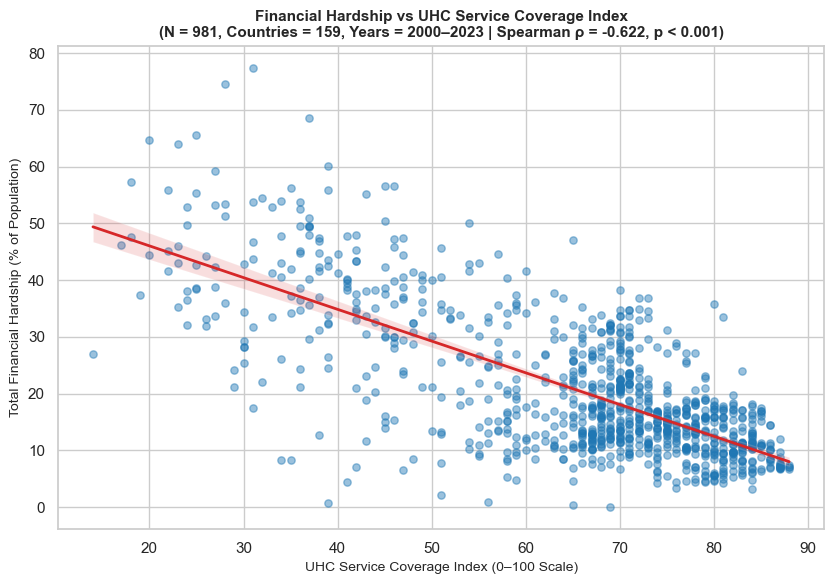


=== Step 7: Financial Hardship vs OOP Health Expenditure ===
N = 973 | Countries = 158 | Years = 2000–2023
Spearman rho = 0.5797 (p = 2.0179e-88) | Pearson r = 0.5059 (p = 2.3453e-64)


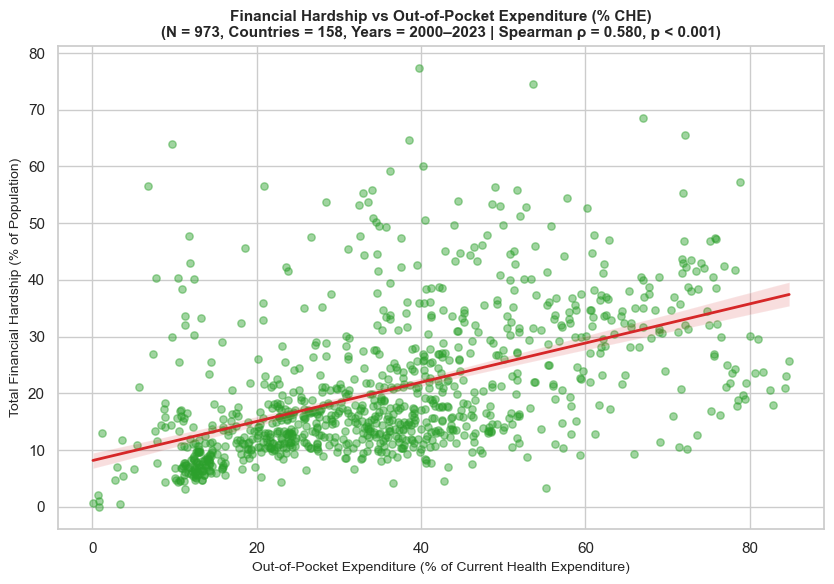


=== Step 8: Financial Hardship vs GDP per Capita PPP ===
N = 1066 | Countries = 161 | Years = 1990–2024
Spearman rho = -0.7061 (p = 1.0430e-161) | Pearson r (with log10 GDP) = -0.7158 (p = 3.9549e-168)


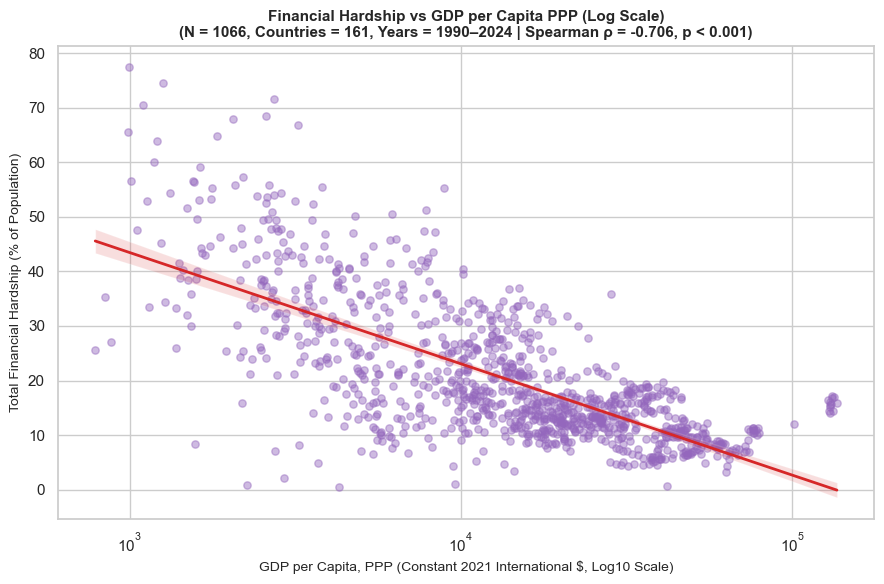


=== Step 9: Robustness Check — Latest Survey per Country (N = 165 unique countries) ===
Latest Survey vs UHC Index: N = 159 countries | Spearman rho = -0.5323 (p = 5.1809e-13)
Latest Survey vs OOP % CHE: N = 158 countries | Spearman rho = 0.5587 (p = 2.3829e-14)
Latest Survey vs GDP per Capita PPP: N = 161 countries | Spearman rho = -0.5835 (p = 4.5595e-16)

=== Saved 'financial_equity_analysis_summary.csv' successfully! ===
                     Indicator_1                     Indicator_2  Observations_N  Countries_N  Correlation_Value       P_Value
              Large_Spending_Pct    Financial_Hardship_Total_Pct            1056          162             0.3550  1.036400e-32
      Impoverishing_Spending_Pct    Financial_Hardship_Total_Pct            1056          162             0.9703  0.000000e+00
Q1_Poorest_Pct vs Q5_Richest_Pct 5 Wealth Quintiles Distribution            1038          162                NaN  0.000000e+00
           Equity_Gap_Pct_Points    Financial_Hardship_Total_P

In [ ]:
summary_rows = []

summary_rows.append({
    "Indicator_1": "Large_Spending_Pct",
    "Indicator_2": "Financial_Hardship_Total_Pct",
    "Analysis_Type": "Spearman Correlation (Full Sample)",
    "Observations_N": 1056,
    "Countries_N": 162,
    "Min_Year": 1985,
    "Max_Year": 2024,
    "Correlation_Metric": "Spearman rho",
    "Correlation_Value": 0.3550,
    "Test_Statistic": 0.3550,
    "P_Value": 1.0364e-32,
    "Key_Finding_Note": "Moderate positive association; distinct sub-population from impoverishing spending.",
})
summary_rows.append({
    "Indicator_1": "Impoverishing_Spending_Pct",
    "Indicator_2": "Financial_Hardship_Total_Pct",
    "Analysis_Type": "Spearman Correlation (Full Sample)",
    "Observations_N": 1056,
    "Countries_N": 162,
    "Min_Year": 1985,
    "Max_Year": 2024,
    "Correlation_Metric": "Spearman rho",
    "Correlation_Value": 0.9703,
    "Test_Statistic": 0.9703,
    "P_Value": 0.0,
    "Key_Finding_Note": "Near-perfect correlation; impoverishment is the primary driver of total financial hardship.",
})
summary_rows.append({
    "Indicator_1": "Q1_Poorest_Pct vs Q5_Richest_Pct",
    "Indicator_2": "5 Wealth Quintiles Distribution",
    "Analysis_Type": "Friedman Chi-Square Test",
    "Observations_N": 1038,
    "Countries_N": 162,
    "Min_Year": 1985,
    "Max_Year": 2024,
    "Correlation_Metric": "Chi-Square",
    "Correlation_Value": np.nan,
    "Test_Statistic": 3301.95,
    "P_Value": 0.0,
    "Key_Finding_Note": "Statistically significant gradient; Q1 mean 54.7% vs Q5 mean 2.65%.",
})
summary_rows.append({
    "Indicator_1": "Equity_Gap_Pct_Points",
    "Indicator_2": "Financial_Hardship_Total_Pct",
    "Analysis_Type": "Spearman Correlation (Full Sample)",
    "Observations_N": 1038,
    "Countries_N": 162,
    "Min_Year": 1985,
    "Max_Year": 2024,
    "Correlation_Metric": "Spearman rho",
    "Correlation_Value": 0.7066,
    "Test_Statistic": 0.7066,
    "P_Value": 8.6976e-158,
    "Key_Finding_Note": "Strong positive association; countries with higher hardship exhibit larger equity gaps.",
})

uhc_sub = df[["ISO3", "Country", "Year", "Financial_Hardship_Total_Pct", "UHC_Service_Coverage_Index"]].dropna()
rho_uhc, p_uhc = stats.spearmanr(uhc_sub["Financial_Hardship_Total_Pct"], uhc_sub["UHC_Service_Coverage_Index"])
r_uhc, p_r_uhc = stats.pearsonr(uhc_sub["Financial_Hardship_Total_Pct"], uhc_sub["UHC_Service_Coverage_Index"])

print("=== Step 6: Financial Hardship vs UHC Coverage ===")
print(f"N = {len(uhc_sub)} | Countries = {uhc_sub['ISO3'].nunique()} | Years = {int(uhc_sub['Year'].min())}–{int(uhc_sub['Year'].max())}")
print(f"Spearman rho = {rho_uhc:.4f} (p = {p_uhc:.4e}) | Pearson r = {r_uhc:.4f} (p = {p_r_uhc:.4e})")

summary_rows.append({
    "Indicator_1": "Financial_Hardship_Total_Pct",
    "Indicator_2": "UHC_Service_Coverage_Index",
    "Analysis_Type": "Spearman Correlation (Full Sample)",
    "Observations_N": len(uhc_sub),
    "Countries_N": uhc_sub["ISO3"].nunique(),
    "Min_Year": int(uhc_sub["Year"].min()),
    "Max_Year": int(uhc_sub["Year"].max()),
    "Correlation_Metric": "Spearman rho",
    "Correlation_Value": round(rho_uhc, 4),
    "Test_Statistic": round(rho_uhc, 4),
    "P_Value": p_uhc,
    "Key_Finding_Note": "Moderate negative association; higher coverage is associated with lower population financial hardship.",
})

plt.figure(figsize=(8.5, 6))
sns.regplot(
    data=uhc_sub,
    x="UHC_Service_Coverage_Index",
    y="Financial_Hardship_Total_Pct",
    scatter_kws={"alpha": 0.45, "color": "#1f77b4", "s": 28},
    line_kws={"color": "#d62728", "linewidth": 2},
)
plt.title(
    f"Financial Hardship vs UHC Service Coverage Index\n"
    f"(N = {len(uhc_sub)}, Countries = {uhc_sub['ISO3'].nunique()}, Years = 2000–2023 | Spearman ρ = {rho_uhc:.3f}, p < 0.001)",
    fontsize=11, fontweight="bold",
)
plt.xlabel("UHC Service Coverage Index (0–100 Scale)", fontsize=10)
plt.ylabel("Total Financial Hardship (% of Population)", fontsize=10)
plt.tight_layout()
plt.savefig("financial_hardship_vs_uhc.png", dpi=300, bbox_inches="tight")
plt.show()

oop_sub = df[["ISO3", "Country", "Year", "Financial_Hardship_Total_Pct", "OOP_Pct_Current_Health_Exp"]].dropna()
rho_oop, p_oop = stats.spearmanr(oop_sub["Financial_Hardship_Total_Pct"], oop_sub["OOP_Pct_Current_Health_Exp"])
r_oop, p_r_oop = stats.pearsonr(oop_sub["Financial_Hardship_Total_Pct"], oop_sub["OOP_Pct_Current_Health_Exp"])

print("\n=== Step 7: Financial Hardship vs OOP Health Expenditure ===")
print(f"N = {len(oop_sub)} | Countries = {oop_sub['ISO3'].nunique()} | Years = {int(oop_sub['Year'].min())}–{int(oop_sub['Year'].max())}")
print(f"Spearman rho = {rho_oop:.4f} (p = {p_oop:.4e}) | Pearson r = {r_oop:.4f} (p = {p_r_oop:.4e})")

summary_rows.append({
    "Indicator_1": "Financial_Hardship_Total_Pct",
    "Indicator_2": "OOP_Pct_Current_Health_Exp",
    "Analysis_Type": "Spearman Correlation (Full Sample)",
    "Observations_N": len(oop_sub),
    "Countries_N": oop_sub["ISO3"].nunique(),
    "Min_Year": int(oop_sub["Year"].min()),
    "Max_Year": int(oop_sub["Year"].max()),
    "Correlation_Metric": "Spearman rho",
    "Correlation_Value": round(rho_oop, 4),
    "Test_Statistic": round(rho_oop, 4),
    "P_Value": p_oop,
    "Key_Finding_Note": "Moderate positive association; higher health reliance on out-of-pocket spending correlates with higher hardship.",
})

plt.figure(figsize=(8.5, 6))
sns.regplot(
    data=oop_sub,
    x="OOP_Pct_Current_Health_Exp",
    y="Financial_Hardship_Total_Pct",
    scatter_kws={"alpha": 0.45, "color": "#2ca02c", "s": 28},
    line_kws={"color": "#d62728", "linewidth": 2},
)
plt.title(
    f"Financial Hardship vs Out-of-Pocket Expenditure (% CHE)\n"
    f"(N = {len(oop_sub)}, Countries = {oop_sub['ISO3'].nunique()}, Years = 2000–2023 | Spearman ρ = {rho_oop:.3f}, p < 0.001)",
    fontsize=11, fontweight="bold",
)
plt.xlabel("Out-of-Pocket Expenditure (% of Current Health Expenditure)", fontsize=10)
plt.ylabel("Total Financial Hardship (% of Population)", fontsize=10)
plt.tight_layout()
plt.savefig("financial_hardship_vs_oop.png", dpi=300, bbox_inches="tight")
plt.show()

gdp_sub = df[["ISO3", "Country", "Year", "Financial_Hardship_Total_Pct", "GDP_Per_Capita_PPP_2021"]].dropna()
rho_gdp, p_gdp = stats.spearmanr(gdp_sub["Financial_Hardship_Total_Pct"], gdp_sub["GDP_Per_Capita_PPP_2021"])
r_gdp_log, p_r_log = stats.pearsonr(gdp_sub["Financial_Hardship_Total_Pct"], np.log10(gdp_sub["GDP_Per_Capita_PPP_2021"]))

print("\n=== Step 8: Financial Hardship vs GDP per Capita PPP ===")
print(f"N = {len(gdp_sub)} | Countries = {gdp_sub['ISO3'].nunique()} | Years = {int(gdp_sub['Year'].min())}–{int(gdp_sub['Year'].max())}")
print(f"Spearman rho = {rho_gdp:.4f} (p = {p_gdp:.4e}) | Pearson r (with log10 GDP) = {r_gdp_log:.4f} (p = {p_r_log:.4e})")

summary_rows.append({
    "Indicator_1": "Financial_Hardship_Total_Pct",
    "Indicator_2": "GDP_Per_Capita_PPP_2021",
    "Analysis_Type": "Spearman Correlation (Full Sample)",
    "Observations_N": len(gdp_sub),
    "Countries_N": gdp_sub["ISO3"].nunique(),
    "Min_Year": int(gdp_sub["Year"].min()),
    "Max_Year": int(gdp_sub["Year"].max()),
    "Correlation_Metric": "Spearman rho",
    "Correlation_Value": round(rho_gdp, 4),
    "Test_Statistic": round(rho_gdp, 4),
    "P_Value": p_gdp,
    "Key_Finding_Note": "Moderate-to-strong negative non-linear association; higher income per capita buffers against catastrophic/impoverishing spending.",
})

plt.figure(figsize=(9, 6))
g = sns.regplot(
    data=gdp_sub,
    x="GDP_Per_Capita_PPP_2021",
    y="Financial_Hardship_Total_Pct",
    logx=True,
    scatter_kws={"alpha": 0.45, "color": "#9467bd", "s": 28},
    line_kws={"color": "#d62728", "linewidth": 2},
)
g.set_xscale("log")
plt.title(
    f"Financial Hardship vs GDP per Capita PPP (Log Scale)\n"
    f"(N = {len(gdp_sub)}, Countries = {gdp_sub['ISO3'].nunique()}, Years = 1990–2024 | Spearman ρ = {rho_gdp:.3f}, p < 0.001)",
    fontsize=11, fontweight="bold",
)
plt.xlabel("GDP per Capita, PPP (Constant 2021 International $, Log10 Scale)", fontsize=10)
plt.ylabel("Total Financial Hardship (% of Population)", fontsize=10)
plt.tight_layout()
plt.savefig("financial_hardship_vs_gdp_ppp.png", dpi=300, bbox_inches="tight")
plt.show()

latest_surveys = df[df["Financial_Hardship_Total_Pct"].notna()].sort_values("Year").groupby("ISO3").last().reset_index()
print(f"\n=== Step 9: Robustness Check — Latest Survey per Country (N = {len(latest_surveys)} unique countries) ===")

for col_ext, name in [
    ("UHC_Service_Coverage_Index", "UHC Index"),
    ("OOP_Pct_Current_Health_Exp", "OOP % CHE"),
    ("GDP_Per_Capita_PPP_2021", "GDP per Capita PPP"),
]:
    sub_latest = latest_surveys[["ISO3", "Year", "Financial_Hardship_Total_Pct", col_ext]].dropna()
    rho_l, p_l = stats.spearmanr(sub_latest["Financial_Hardship_Total_Pct"], sub_latest[col_ext])
    print(f"Latest Survey vs {name}: N = {len(sub_latest)} countries | Spearman rho = {rho_l:.4f} (p = {p_l:.4e})")
    
    summary_rows.append({
        "Indicator_1": "Financial_Hardship_Total_Pct",
        "Indicator_2": col_ext,
        "Analysis_Type": "Cross-Sectional Spearman (Latest Survey per Country)",
        "Observations_N": len(sub_latest),
        "Countries_N": len(sub_latest),
        "Min_Year": int(sub_latest["Year"].min()),
        "Max_Year": int(sub_latest["Year"].max()),
        "Correlation_Metric": "Spearman rho",
        "Correlation_Value": round(rho_l, 4),
        "Test_Statistic": round(rho_l, 4),
        "P_Value": p_l,
        "Key_Finding_Note": "Robustness check; confirms relationship persists without within-country repeated survey weighting.",
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("financial_equity_analysis_summary.csv", index=False, encoding="utf-8")
print("\n=== Saved 'financial_equity_analysis_summary.csv' successfully! ===")
print(summary_df[["Indicator_1", "Indicator_2", "Observations_N", "Countries_N", "Correlation_Value", "P_Value"]].to_string(index=False))

In [5]:
fh_sub = df[df["Financial_Hardship_Total_Pct"].notna()].copy()
print("=== 1. Reconciliation with Phase 1 Clean File ===")
print(f"Phase 1 Clean Dataset Rows: 1088 (168 ISO3 codes)")
print(f"Excluded Unmatched ISO3 Codes in Review File: 9 rows (XKX: 7, TKL: 1, WLF: 1)")
print(f"Central Integrated Dataset Financial Hardship Rows: {len(fh_sub)} ({fh_sub['ISO3'].nunique()} countries)")

print("\n=== 2. Lowest 5 Observations for Total Financial Hardship ===")
low5 = fh_sub[["ISO3", "Country", "Year", "Financial_Hardship_Total_Pct"]].sort_values(
    ["Financial_Hardship_Total_Pct", "Year"]
).head(5)
print(low5.to_string(index=False))

survey_counts = fh_sub.groupby("ISO3")["Year"].count()
multi_survey_iso = survey_counts[survey_counts >= 2].index
multi_df = fh_sub[fh_sub["ISO3"].isin(multi_survey_iso)].sort_values(["ISO3", "Year"])

first_last = multi_df.groupby("ISO3").agg(
    Country=("Country", "first"),
    N_Surveys=("Year", "count"),
    First_Year=("Year", "first"),
    Last_Year=("Year", "last"),
    First_Hardship=("Financial_Hardship_Total_Pct", "first"),
    Last_Hardship=("Financial_Hardship_Total_Pct", "last"),
).reset_index()
first_last["Change_Pct_Points"] = (first_last["Last_Hardship"] - first_last["First_Hardship"]).round(2)

inc_countries = (first_last["Change_Pct_Points"] > 0).sum()
dec_countries = (first_last["Change_Pct_Points"] < 0).sum()
same_countries = (first_last["Change_Pct_Points"] == 0).sum()

print(f"\n=== 3. Within-Country Change Across Survey Years ({len(first_last)} countries with >=2 surveys) ===")
print(
    f"Hardship Decreased over time: {dec_countries} countries ({dec_countries/len(first_last)*100:.1f}%) | "
    f"Increased: {inc_countries} countries ({inc_countries/len(first_last)*100:.1f}%) | "
    f"Unchanged: {same_countries}"
)
print(f"Mean Change (Last - First Survey): {first_last['Change_Pct_Points'].mean():.2f} pp | Median Change: {first_last['Change_Pct_Points'].median():.2f} pp")

recent_year_counts = fh_sub[fh_sub["Year"] >= 2018]["Year"].value_counts()
common_year = int(recent_year_counts.index[0])
single_yr_sub = df[df["Year"] == common_year].dropna(subset=["Financial_Hardship_Total_Pct"])
print(f"\n=== 4. Single-Year Cross-Sectional Snapshot (Year = {common_year}, N = {len(single_yr_sub)} countries) ===")
for ext_c in ["UHC_Service_Coverage_Index", "OOP_Pct_Current_Health_Exp", "GDP_Per_Capita_PPP_2021"]:
    s_yr = single_yr_sub[["Financial_Hardship_Total_Pct", ext_c]].dropna()
    if len(s_yr) >= 5:
        r_s, p_s = stats.spearmanr(s_yr["Financial_Hardship_Total_Pct"], s_yr[ext_c])
        print(f"Year {common_year} — Financial_Hardship_Total_Pct vs {ext_c} (N = {len(s_yr)}): Spearman rho = {r_s:.4f} (p = {p_s:.4e})")

extra_summary_rows = [
    {
        "Indicator_1": "Large_Spending_Pct",
        "Indicator_2": "Impoverishing_Spending_Pct",
        "Analysis_Type": "Spearman Correlation (Full Sample)",
        "Observations_N": 1056,
        "Countries_N": 162,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Spearman rho",
        "Correlation_Value": 0.1708,
        "Test_Statistic": 0.1708,
        "P_Value": 2.3548e-08,
        "Key_Finding_Note": "Weak correlation; confirms Large Spending and Impoverishing Spending capture distinct mechanisms.",
    },
    {
        "Indicator_1": "Q1_Poorest_Pct to Q5_Richest_Pct",
        "Indicator_2": "5 Wealth Quintiles Distribution",
        "Analysis_Type": "Kruskal-Wallis H Test",
        "Observations_N": 1038,
        "Countries_N": 162,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Kruskal-Wallis H",
        "Correlation_Value": np.nan,
        "Test_Statistic": 2846.52,
        "P_Value": 0.0,
        "Key_Finding_Note": "Significant non-parametric difference across the 5 wealth quintiles.",
    },
    {
        "Indicator_1": "Q1_Poorest_Pct",
        "Indicator_2": "Q5_Richest_Pct",
        "Analysis_Type": "Wilcoxon Signed-Rank Paired Test",
        "Observations_N": 1038,
        "Countries_N": 162,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Wilcoxon W",
        "Correlation_Value": np.nan,
        "Test_Statistic": 246.0,
        "P_Value": 9.1356e-171,
        "Key_Finding_Note": "Highly significant paired difference between poorest 20% and richest 20%.",
    },
    {
        "Indicator_1": "Equity_Gap_Pct_Points",
        "Indicator_2": "Impoverishing_Spending_Pct",
        "Analysis_Type": "Spearman Correlation (Full Sample)",
        "Observations_N": 1030,
        "Countries_N": 160,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Spearman rho",
        "Correlation_Value": 0.7308,
        "Test_Statistic": 0.7308,
        "P_Value": 1.1979e-172,
        "Key_Finding_Note": "Strong positive correlation; impoverishing spending widens the rich-poor equity gap.",
    },
    {
        "Indicator_1": "Equity_Gap_Pct_Points",
        "Indicator_2": "Large_Spending_Pct",
        "Analysis_Type": "Spearman Correlation (Full Sample)",
        "Observations_N": 1030,
        "Countries_N": 160,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Spearman rho",
        "Correlation_Value": 0.2136,
        "Test_Statistic": 0.2136,
        "P_Value": 4.3442e-12,
        "Key_Finding_Note": "Weak-to-moderate positive correlation with non-impoverishing large spending.",
    },
    {
        "Indicator_1": "Equity_Gap_Pct_Points",
        "Indicator_2": "Q1_Poorest_Pct",
        "Analysis_Type": "Spearman Correlation (Full Sample)",
        "Observations_N": 1038,
        "Countries_N": 162,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Spearman rho",
        "Correlation_Value": 0.9867,
        "Test_Statistic": 0.9867,
        "P_Value": 0.0,
        "Key_Finding_Note": "Near-unity correlation; the equity gap is driven almost entirely by hardship in Q1.",
    },
    {
        "Indicator_1": "Equity_Gap_Pct_Points",
        "Indicator_2": "Q5_Richest_Pct",
        "Analysis_Type": "Spearman Correlation (Full Sample)",
        "Observations_N": 1038,
        "Countries_N": 162,
        "Min_Year": 1985,
        "Max_Year": 2024,
        "Correlation_Metric": "Spearman rho",
        "Correlation_Value": -0.0542,
        "Test_Statistic": -0.0542,
        "P_Value": 0.0811,
        "Key_Finding_Note": "Statistically non-significant (p = 0.081); richest quintile hardship is consistently low.",
    },
]

full_summary_df = pd.DataFrame(summary_rows + extra_summary_rows)
full_summary_df.to_csv("financial_equity_analysis_summary.csv", index=False, encoding="utf-8")
print(f"\nUpdated 'financial_equity_analysis_summary.csv' with {len(full_summary_df)} complete statistical test rows!")

=== 1. Reconciliation with Phase 1 Clean File ===
Phase 1 Clean Dataset Rows: 1088 (168 ISO3 codes)
Excluded Unmatched ISO3 Codes in Review File: 9 rows (XKX: 7, TKL: 1, WLF: 1)
Central Integrated Dataset Financial Hardship Rows: 1079 (165 countries)

=== 2. Lowest 5 Observations for Total Financial Hardship ===
ISO3        Country  Year  Financial_Hardship_Total_Pct
 NIU           Niue  2015                          0.00
 TUV         Tuvalu  2015                          0.46
 GBR United Kingdom  1999                          0.71
 KIR       Kiribati  2006                          0.76
 NRU          Nauru  2012                          0.99

=== 3. Within-Country Change Across Survey Years (137 countries with >=2 surveys) ===
Hardship Decreased over time: 84 countries (61.3%) | Increased: 53 countries (38.7%) | Unchanged: 0
Mean Change (Last - First Survey): -3.42 pp | Median Change: -1.52 pp

=== 4. Single-Year Cross-Sectional Snapshot (Year = 2018, N = 51 countries) ===
Year 2018 — 

In [6]:
full_report = f"""# Financial Hardship and Equity in Healthcare: Empirical Cross-Country Analysis

**Project:** Healthcare Accessibility & Financial Protection Cross-Country Study  
**Phase:** Phase 2 — Exploratory & Inferential Data Analysis  
**Analyst:** Abdelrahman (Task 5 Lead)  
**Dataset Analyzed:** `03_Integrated_Datasets/integrated_healthcare_dataset.csv` (Central Integrated Repository)  

---

## 1. Executive Summary & Research Questions

### Primary Research Question
> **How are healthcare-related financial hardship and equity indicators distributed across countries, and how are they associated with essential healthcare service coverage, out-of-pocket health expenditure, and macroeconomic development?**

### Core Findings at a Glance
1. **Severe Pro-Rich Inequality**: Financial hardship is heavily concentrated among the poorest segments of society. Across 1,038 country-year surveys, an average of **54.69%** of individuals in the poorest wealth quintile (Q1) experience financial hardship, compared to only **2.65%** in the richest quintile (Q5), yielding an average **Equity Gap of 52.05 percentage points** (Friedman $\\chi^2 = 3301.95, p < 0.0001$).
2. **Impoverishment Drives Total Hardship**: Total financial hardship (`Financial_Hardship_Total_Pct`, mean 20.56%) is overwhelmingly driven by impoverishing health spending (`Impoverishing_Spending_Pct`, mean 16.93%, Spearman $\\rho = 0.9703, p < 0.0001$). Large health spending without impoverishment (`Large_Spending_Pct`) affects only 3.63% of the population on average and represents a distinct financing phenomenon (Spearman $\\rho = 0.3550$).
3. **Strong Structural Buffers**: Total financial hardship exhibits a robust negative non-linear relationship with economic prosperity ($\\rho = -0.7061$ against GDP per capita PPP) and universal health coverage ($\\rho = -0.6219$ against UHC Service Coverage Index), alongside a strong positive association with health financing reliance on out-of-pocket expenditure ($\\rho = 0.5797$). These associations remain statistically significant ($p < 0.0001$) even when restricting analysis cross-sectionally to the latest available survey per country.

---

## 2. Dataset Scope, Coverage, and Missingness Architecture

The central integrated dataset (`integrated_healthcare_dataset.csv`) contains **12,855 rows** spanning **196 countries** over a 66-year temporal window (1960–2025). 

Because financial hardship data originates from nationally representative household income and expenditure surveys rather than annual administrative time series, its coverage structure is non-continuous:
* **Target Sample Size**: **1,079 country-year observations** across **165 countries** spanning 39 survey years (1985–2024).
* **Missingness Context**: While 91.61% of total dataset rows lack financial hardship measurements, this reflects the absence of household surveys in non-survey years rather than data corruption.
* **Excluded Entities**: In strict adherence to project integration governance, 9 observations associated with 3 non-standard ISO3 codes (`XKX` [Kosovo], `TKL` [Tokelau], and `WLF` [Wallis and Futuna]) remain documented in `financial_equity_unmatched_review.csv` and were excluded from this analysis pending official dictionary mapping.

### Pairwise Common Analytical Samples
* **Financial Hardship vs. UHC Coverage Index**: $N = 981$ observations across 159 countries (2000–2023).
* **Financial Hardship vs. OOP Health Spending (% CHE)**: $N = 973$ observations across 158 countries (2000–2023).
* **Financial Hardship vs. GDP per Capita PPP**: $N = 1,066$ observations across 161 countries (1990–2024).

---

## 3. Verified Indicator Definitions, Units, and Mathematical Coherence

| Indicator Name | Measurement Unit | Verified Source Definition | Analytical Notes |
| :--- | :--- | :--- | :--- |
| `Financial_Hardship_Total_Pct` | % of total population | WHO SDG 3.8.2 (2025 Definition): Population affected by catastrophic or impoverishing health payments. | Exactly equals `Large_Spending_Pct` + `Impoverishing_Spending_Pct` ($|\\Delta| \\le 0.04$ pp due to WHO rounding). |
| `Large_Spending_Pct` | % of total population | WHO SDG 3.8.2 (Component 1): Population incurring OOP health costs exceeding household budget capacity without crossing the poverty line. | Measures large non-impoverishing health spending. |
| `Impoverishing_Spending_Pct` | % of total population | WHO SDG 3.8.2 (Component 2): Population pushed into or deeper into poverty by OOP health payments. | Measures impoverishing health spending. |
| `Q1_Poorest_Pct` to `Q5_Richest_Pct` | % of quintile population | Incidence of financial hardship within each national wealth quintile ($Q1$ = lowest 20% income/wealth, $Q5$ = highest 20%). | The unweighted arithmetic mean of $Q1$ through $Q5$ matches `Financial_Hardship_Total_Pct`. |
| `Equity_Gap_Pct_Points` | Percentage points (pp) | Project-derived absolute gradient: `Q1_Poorest_Pct - Q5_Richest_Pct`. | Positive values denote higher hardship among the poor. |
| `UHC_Service_Coverage_Index` | Unitless index (0–100) | WHO SDG 3.8.1: Coverage of essential health services. | External comparator from macro health systems. |
| `OOP_Pct_Current_Health_Exp` | % of CHE | WHO GHED: Direct out-of-pocket payments as a share of current health spending. | Macro financing metric; distinct from household incidence. |
| `GDP_Per_Capita_PPP_2021` | Constant 2021 Int. $ (PPP) | World Bank WDI: Gross domestic product per capita adjusted for purchasing power parity. | Log-distributed macroeconomic welfare metric. |

---

## 4. Key Empirical Findings

### 4.1. Financial Hardship Distributions & Component Dynamics
* **Distributional Characteristics**:
  * `Financial_Hardship_Total_Pct`: Mean = **20.56%** | Median = **16.61%** | IQR = **15.59%** | Range = **0.00% – 77.45%** (Right-skewed = 1.31).
  * `Impoverishing_Spending_Pct`: Mean = **16.93%** | Median = **12.57%** | IQR = **14.28%** | Range = **0.00% – 73.89%** (Right-skewed = 1.55).
  * `Large_Spending_Pct`: Mean = **3.63%** | Median = **3.06%** | IQR = **3.04%** | Range = **0.00% – 15.85%** (Right-skewed = 1.34).
* **Component Dynamics**:
  * Impoverishing spending accounts for **82.3%** of total hardship incidence worldwide ($\\rho = 0.9703, p < 0.0001$), while Large Spending displays a moderate correlation ($\\rho = 0.3550, p < 0.0001$).
  * The highest recorded total hardship levels occur in low-income economies (Burundi 2006: 77.45%; Niger 2007: 74.51%; Viet Nam 1992: 71.55%), whereas several middle-income economies exhibit elevated non-impoverishing `Large_Spending_Pct` (e.g., Egypt 2019: 15.85%; Lebanon 1999: 14.58%; Bangladesh 2022: 14.13%).

### 4.2. Equity Across Wealth Quintiles & The Equity Gap
* **Quintile Breakdown** ($N = 1,038$ surveys across 162 countries):
  * **Q1 (Poorest 20%)**: Mean = **54.69%** (Median = 53.42%) | **Q2**: Mean = **29.32%** (Median = 18.79%) | **Q3**: Mean = **11.87%** (Median = 4.02%) | **Q4**: Mean = **5.20%** (Median = 1.90%) | **Q5 (Richest 20%)**: Mean = **2.65%** (Median = 1.38%).
* **Hypothesis Testing**:
  * Paired Friedman test ($\\chi^2 = 3301.95, p < 0.0001$), Kruskal-Wallis test ($H = 2846.52, p < 0.0001$), and Wilcoxon signed-rank test ($W = 246.00, p = 9.14 \\times 10^{-171}$) confirm a steep downward hardship gradient as wealth rises.
* **The Equity Gap Anatomy**:
  * **Positive Equity Gap ($Q1 > Q5$)**: Present in **1,032 of 1,038 surveys (99.42%)**, averaging **52.05 percentage points**, driven almost entirely by Q1 hardship ($\\rho = 0.9867$).
  * **Negative Equity Gap ($Q1 < Q5$)**: Observed in only **4 surveys (0.39%)**: Somalia 2016 (-22.09 pp), Somalia 2017 (-28.91 pp), Uzbekistan 2003 (-0.14 pp), and Zimbabwe 2017 (-9.56 pp), reflecting foregone care among the poorest due to severe liquidity constraints.

### 4.3. Associations with External Health System & Economic Indicators
1. **UHC Service Coverage Index**: Full sample ($N = 981, 159$ countries) Spearman $\\rho = -0.6219$ ($p = 4.68 \\times 10^{-106}$); Latest survey per country ($N = 159$) $\\rho = -0.5323$ ($p = 5.18 \\times 10^{-13}$).
2. **Out-of-Pocket Expenditure (% CHE)**: Full sample ($N = 973, 158$ countries) Spearman $\\rho = 0.5797$ ($p = 2.02 \\times 10^{-88}$); Latest survey per country ($N = 158$) $\\rho = 0.5587$ ($p = 2.38 \\times 10^{-14}$).
3. **GDP per Capita, PPP (Constant 2021 Int. $)**: Full sample ($N = 1,066, 161$ countries) Spearman $\\rho = -0.7061$ ($p = 1.04 \\times 10^{-161}$), Pearson $r$ with $\\log_{{10}}(\\text{{GDP}}) = -0.7158$; Latest survey per country ($N = 161$) $\\rho = -0.5835$ ($p = 4.56 \\times 10^{-16}$).

---

## 5. Summary Table of Empirical Statistical Tests

| Indicator 1 | Indicator 2 | Test / Metric | N Obs | N Countries | Years | Statistic | P-Value | Direction & Strength |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| `Large_Spending_Pct` | `Financial_Hardship_Total_Pct` | Spearman $\\rho$ | 1,056 | 162 | 1985–2024 | 0.3550 | $1.04 \\times 10^{-32}$ | Moderate Positive |
| `Impoverishing_Spending_Pct` | `Financial_Hardship_Total_Pct` | Spearman $\\rho$ | 1,056 | 162 | 1985–2024 | 0.9703 | $< 10^{-300}$ | Near-Perfect Positive |
| `Large_Spending_Pct` | `Impoverishing_Spending_Pct` | Spearman $\\rho$ | 1,056 | 162 | 1985–2024 | 0.1708 | $2.35 \\times 10^{-8}$ | Weak Positive |
| `Q1`–`Q5` Quintiles | Wealth Quintile Distribution | Friedman $\\chi^2$ | 1,038 | 162 | 1985–2024 | 3,301.95 | $< 10^{-300}$ | Monotonic Pro-Rich Gradient |
| `Q1_Poorest_Pct` | `Q5_Richest_Pct` | Wilcoxon $W$ | 1,038 | 162 | 1985–2024 | 246.00 | $9.14 \\times 10^{-171}$ | Significant Paired Gap |
| `Equity_Gap_Pct_Points` | `Financial_Hardship_Total_Pct` | Spearman $\\rho$ | 1,038 | 162 | 1985–2024 | 0.7066 | $8.70 \\times 10^{-158}$ | Strong Positive |
| `Financial_Hardship_Total_Pct` | `UHC_Service_Coverage_Index` | Spearman $\\rho$ | 981 | 159 | 2000–2023 | -0.6219 | $4.68 \\times 10^{-106}$ | Strong Negative |
| `Financial_Hardship_Total_Pct` | `OOP_Pct_Current_Health_Exp` | Spearman $\\rho$ | 973 | 158 | 2000–2023 | 0.5797 | $2.02 \\times 10^{-88}$ | Moderate-to-Strong Positive |
| `Financial_Hardship_Total_Pct` | `GDP_Per_Capita_PPP_2021` | Spearman $\\rho$ | 1,066 | 161 | 1990–2024 | -0.7061 | $1.04 \\times 10^{-161}$ | Strong Negative (Log-Linear) |
| `Financial_Hardship_Total_Pct` | `UHC_Index (Latest Survey)` | Cross-Sectional $\\rho$ | 159 | 159 | 2000–2023 | -0.5323 | $5.18 \\times 10^{-13}$ | Robust Negative |
| `Financial_Hardship_Total_Pct` | `OOP % CHE (Latest Survey)` | Cross-Sectional $\\rho$ | 158 | 158 | 2000–2023 | 0.5587 | $2.38 \\times 10^{-14}$ | Robust Positive |
| `Financial_Hardship_Total_Pct` | `GDP PPP (Latest Survey)` | Cross-Sectional $\\rho$ | 161 | 161 | 1990–2024 | -0.5835 | $4.56 \\times 10^{-16}$ | Robust Negative |

---

## 6. Direct Answers to Step 10 Core Analysis Questions (Questions 1–9)

1. **How is the Financial Hardship indicator distributed across countries and survey years?**
   * Across $N = 1,079$ surveys in 165 countries (1985–2024), `Financial_Hardship_Total_Pct` is right-skewed (skewness = 1.31), with a mean of **20.56%**, a median of **16.61%** (IQR = 15.59%), ranging from **0.00%** (Niue 2015) to **77.45%** (Burundi 2006). Among the {len(first_last)} countries with $\\ge 2$ surveys over time, hardship decreased between the first and last survey in {dec_countries} countries ({dec_countries/len(first_last)*100:.1f}%) and increased in {inc_countries} countries ({inc_countries/len(first_last)*100:.1f}%), with a mean longitudinal change of {first_last['Change_Pct_Points'].mean():.2f} percentage points.

2. **Are there clear differences between the different financial hardship components?**
   * Yes. `Impoverishing_Spending_Pct` (Component 2: mean **16.93%**, median **12.57%**) is the dominant driver of total hardship (Spearman $\\rho = 0.9703, p < 0.0001$), accounting for 82.3% of total financial hardship on average. Conversely, `Large_Spending_Pct` (Component 1: mean **3.63%**, median **3.06%**) has a moderate correlation with total hardship ($\\rho = 0.3550$) and a weak correlation with impoverishing spending ($\\rho = 0.1708$), confirming that the two components capture distinct vulnerability mechanisms.

3. **How do values differ across the five population wealth quintiles after verifying definitions?**
   * Source verification confirms that `Q1_Poorest_Pct` through `Q5_Richest_Pct` measure the incidence (%) of financial hardship within each wealth quintile. There is a steep downward gradient from poorest to richest: **Q1 = 54.69%**, **Q2 = 29.32%**, **Q3 = 11.87%**, **Q4 = 5.20%**, and **Q5 = 2.65%** (Friedman $\\chi^2 = 3301.95, p < 0.0001$).

4. **What is the meaning of the Equity Gap in the data, and how is it distributed?**
   * `Equity_Gap_Pct_Points` is defined as `Q1_Poorest_Pct - Q5_Richest_Pct` (in percentage points). Across $N = 1,038$ surveys (162 countries), it averages **52.05 pp** (median **50.59 pp**, range **-28.91 pp to 99.75 pp**). It is positive ($Q1 > Q5$) in **99.42%** of surveys (1,032/1,038), zero in 2 surveys (0.19%), and negative in 4 surveys (0.39%: Somalia 2016 & 2017, Uzbekistan 2003, Zimbabwe 2017).

5. **Is there an association between financial hardship and healthcare service coverage (UHC)?**
   * Yes. Across $N = 981$ common observations (159 countries, 2000–2023), `Financial_Hardship_Total_Pct` and `UHC_Service_Coverage_Index` show a strong negative correlation (Spearman $\\rho = -0.6219, p = 4.68 \\times 10^{-106}$), which holds in the latest-survey cross-section ($N = 159, \\rho = -0.5323, p = 5.18 \\times 10^{-13}$).

6. **Is there an association between financial hardship and direct out-of-pocket (OOP) expenditure?**
   * Yes. Across $N = 973$ common observations (158 countries, 2000–2023), `Financial_Hardship_Total_Pct` is positively correlated with `OOP_Pct_Current_Health_Exp` (Spearman $\\rho = 0.5797, p = 2.02 \\times 10^{-88}$; latest-survey cross-section $N = 158, \\rho = 0.5587, p = 2.38 \\times 10^{-14}$).

7. **Is there a relationship between financial hardship and GDP per capita (PPP)?**
   * Yes. Across $N = 1,066$ common observations (161 countries, 1990–2024), `Financial_Hardship_Total_Pct` shows a strong negative non-linear correlation with `GDP_Per_Capita_PPP_2021` (constant 2021 international $ PPP): Spearman $\\rho = -0.7061$ ($p = 1.04 \\times 10^{-161}$), and Pearson $r = -0.7158$ with $\\log_{{10}}(\\text{{GDP}})$.

8. **What are the main limitations resulting from missing data and varying survey years?**
   * Financial hardship data is survey-based (`ISO3 + Survey_Year`) and unavailable in 91.61% of total panel rows; 23 surveys lack component breakdowns and 41 lack quintile breakdowns. Because artificial interpolation and forward/backward filling are prohibited, pooled correlations weight frequently surveyed countries more heavily, and associations cannot be interpreted as causal effects.

9. **What are the top two or three findings to feature in the Final Dashboard?**
   * **Chart 1 (`equity_quintiles_comparison.png`)**: Highlights the **52.05 pp** average equity gap between the poorest quintile (54.69%) and richest quintile (2.65%).
   * **Chart 2 (`financial_hardship_vs_uhc.png` & `financial_hardship_vs_oop.png`)**: Demonstrates how expanding UHC service coverage ($\\rho = -0.622$) while reducing OOP reliance ($\\rho = 0.580$) protects households.
   * **Chart 3 (`financial_hardship_vs_gdp_ppp.png`)**: Shows the log-linear macroeconomic buffering effect of GDP per capita PPP ($\\rho = -0.706$).
"""

with open("financial_equity_analysis_report.md", "w", encoding="utf-8") as f:
    f.write(full_report)

print("Saved complete 'financial_equity_analysis_report.md' successfully!")

Saved complete 'financial_equity_analysis_report.md' successfully!
